# WaveDispX 开算前审核 Notebook

## Goal

在不运行波场正演的情况下，先审核模型、密度、源—检波器几何、主动子波或被动 PSD、随机源样例、理论频散以及采样/混叠风险。只有人工确认后，才在最后一个单元显式开启正演。

## Setup

默认审核正式被动算例。要审核主动算例，只需把下面的 `CONFIG_RELATIVE_PATH` 改为 `examples/active_two_layer.toml`。建议在 JupyterLab/VS Code 中把 TOML 与本 Notebook 并排打开，修改后从本节开始重新运行。

In [1]:
from pathlib import Path
from IPython import get_ipython
from IPython.display import Markdown, display

get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt

from wavedispx.config import load_config
from wavedispx.preflight import (
    build_preflight_review,
    checks_markdown,
    plot_preflight_review,
    save_preflight_review,
)
from wavedispx.runner import run

candidate_roots = (Path.cwd(), Path.cwd().parent)
PROJECT_ROOT = next(path for path in candidate_roots if (path / 'examples').is_dir())
print(f'Project root: {PROJECT_ROOT}')

Project root: /Volumes/lx_exFAT/PassiveFW_versionstable


In [2]:
# 只需修改这里：主动用 examples/active_two_layer.toml
CONFIG_RELATIVE_PATH = Path('examples/passive_two_layer.toml')
PREFLIGHT_OUTPUT = PROJECT_ROOT / 'output_python' / 'notebook_preflight'

# 安全开关：审核阶段必须保持 False。看完全部图和检查表后再手动改为 True。
CONFIRM_AND_RUN = False

## Steps

### 1. 加载并解析输入

In [3]:
config_path = (PROJECT_ROOT / CONFIG_RELATIVE_PATH).resolve()
config = load_config(config_path)
review = build_preflight_review(config)

summary = [
    f'**配置文件：** `{config_path}`',
    f'**模式：** `{config.mode}`',
    f'**模型层数：** {len(config.model.layers)}',
    f'**检波器：** {review.geometry.receiver_x_m.size}，排列长度 {review.diagnostics["receiver_aperture_m"]:.1f} m',
    f'**源数：** {review.geometry.source_x_m.size}',
    f'**处理频带：** {config.processing.frequency_min_hz:g}–{config.processing.frequency_max_hz:g} Hz',
    f'**频散方法：** `{config.processing.dispersion_method}`',
]
display(Markdown('  \n'.join(summary)))

**配置文件：** `/Volumes/lx_exFAT/PassiveFW_versionstable/examples/passive_two_layer.toml`  
**模式：** `passive`  
**模型层数：** 2  
**检波器：** 121，排列长度 600.0 m  
**源数：** 384  
**处理频带：** 5–18.8 Hz  
**频散方法：** `phase_shift`

### 2. 绘制输入审核图

六联图包括 `Vp/Vs`、密度、源—检波器几何、源时间函数、功率谱/PSD 和处理窗口内的理论频散。此步骤不计算 Green 函数。

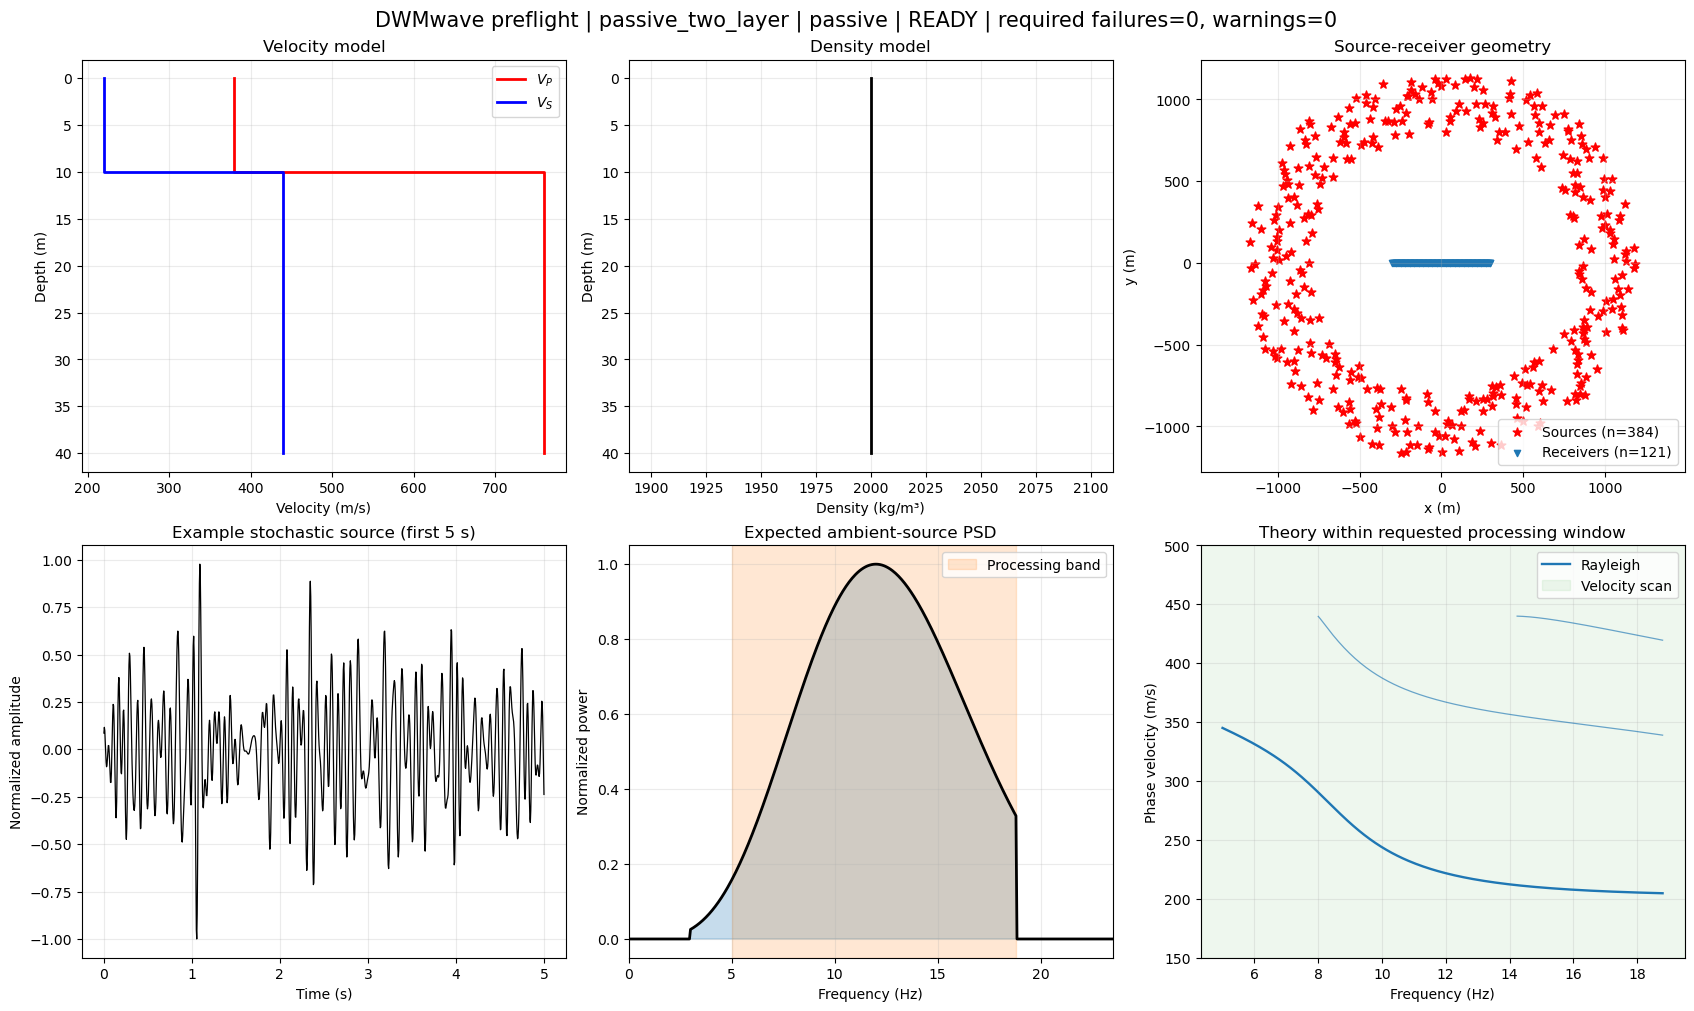

{'figure': PosixPath('/Volumes/lx_exFAT/PassiveFW_versionstable/output_python/notebook_preflight/preflight.png'),
 'report': PosixPath('/Volumes/lx_exFAT/PassiveFW_versionstable/output_python/notebook_preflight/preflight_report.json'),
 'receivers': PosixPath('/Volumes/lx_exFAT/PassiveFW_versionstable/output_python/notebook_preflight/receivers.csv'),
 'sources': PosixPath('/Volumes/lx_exFAT/PassiveFW_versionstable/output_python/notebook_preflight/sources.csv'),
 'source_preview': PosixPath('/Volumes/lx_exFAT/PassiveFW_versionstable/output_python/notebook_preflight/source_preview.csv')}

In [4]:
figure = plot_preflight_review(review)
display(figure)
plt.close(figure)

preflight_artifacts = save_preflight_review(review, PREFLIGHT_OUTPUT)
preflight_artifacts

## Checks

### 3. 查看自动检查

`required` 检查失败时禁止开算；建议项失败会显示警告，可结合研究目标人工决定。

In [5]:
display(Markdown(checks_markdown(review)))
print(f'Preflight ready: {review.ready}')

| Status | Check | Value | Criterion |
|---|---|---:|---|
| ✅ PASS | Temporal Nyquist | 100.00 Hz | > source cutoff 18.80 Hz |
| ✅ PASS | Samples per shortest period | 10.6 | >= 8 recommended |
| ✅ PASS | Spatial alias estimate | 20.47 Hz | >= processing maximum 18.80 Hz |
| ✅ PASS | Aperture at minimum frequency | 8.69 wavelengths | >= 2 wavelengths recommended |
| ✅ PASS | Minimum source-receiver distance | 510.73 m | > 0 m |
| ✅ PASS | Correlation window | 20.00 s | > required lag 3.94 s |
| ✅ PASS | Ambient source count | 384 | >= 192 recommended for diffuse annular illumination |
| ✅ PASS | Maximum source azimuth gap | 1.80° | <= 10° recommended for annular illumination |
| ✅ PASS | Radial Green interpolation step | 0.500 m | <= 0.585 m |

Preflight ready: True


### 当前正式被动模板的预检图（无需执行即可查看）

![Passive preflight](../output_python/preflight_passive/preflight.png)

## Next Steps

### 4. 人工确认后再启动正演

先逐项确认模型界面、速度和密度单位、源位置/方位覆盖、道间距、排列长度、子波/PSD 频带及理论曲线是否都符合预期。确认后回到顶部，把 `CONFIRM_AND_RUN` 改为 `True`，再单独运行下面这个单元。

In [6]:
if not review.ready:
    raise RuntimeError('Required preflight checks failed; fix the TOML before forward modelling.')

if CONFIRM_AND_RUN:
    run_artifacts = run(config)
    print(f'Forward modelling complete: {run_artifacts.output_directory}')
else:
    print('Forward modelling NOT started. Review the figure and checks, then set CONFIRM_AND_RUN=True.')

Forward modelling NOT started. Review the figure and checks, then set CONFIRM_AND_RUN=True.
